# PySNE Tutorial
## Finding All Solutions with *Spiral Optimization Algorithm* (SPO) + Clustering

PySNE is a Python library for finding all solutions of:
1. Systems of Nonlinear Equations (SNE),
2. Diophantine Equations (integer solutions), and
3. All optima of multimodal functions,

using the *Spiral Dynamics Optimization Algorithm* with clustering technique.

References:
- Sidarto, K. A. & Kania, A. (2015). *Finding all solutions of systems of nonlinear equations using spiral dynamics inspired optimization with clustering.* JACIII, 19(5).
- Sidarto, K. A., Kania, A., & Sumarti, N. (2017). *Finding multiple solutions of multimodal optimization using spiral optimization algorithm with clustering.* MENDEL, 23(1).
- Sumarti, N., et al. (2023). A method for finding numerical solutions to diophantine equations using spiral optimization algorithm with clustering. Applied Soft Computing.
- Tamura, K. & Yasuda, K. (2011). *Spiral Dynamics Inspired Optimization.* JACIII, 15(8).

Tutorial roadmap:
1. Installation (development mode)
2. Spiral Optimization (SPO) — single-objective optimization
3. Finding SNE roots via transformation — still a single solution
4. Clustering — finding all roots
5. Diophantine equations (integer solutions)
6. Mixed-Integer (Real Case)
7. Multimodal optimization — all optima

## 1. Installation

PySNE is still under development and has not yet been published on PyPI, so installation is done directly from the GitHub repository (`main` branch):

In [ ]:
# Install from GitHub (development mode).
!pip install git+https://github.com/p2ms-optimization/pysne.git

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

  Cloning https://github.com/p2ms-optimization/pysne.git to /tmp/pip-req-build-npuhfng1
  Running command git clone --filter=blob:none --quiet https://github.com/p2ms-optimization/pysne.git /tmp/pip-req-build-npuhfng1
  Resolved https://github.com/p2ms-optimization/pysne.git to commit 6b17260909fa0550ba9167f891445ff8c8414b52
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pysne: filename=pysne-0.1.0-py3-none-any.whl size=37960 sha256=8ef06abf3d1e29691cdef8d93913bb3d3e8d5ed657c01850f272a1318aa71674
  Stored in directory: /tmp/pip-ephem-wheel-cache-84amu5e9/wheels/23/72/da/d9bc4e06b7ed29e5e315fa5955edc5f44d92644ae864906b01
Successfully built pysne


## 2. Spiral Optimization (SPO) — single-objective optimization

Before diving into finding all solutions, let’s first understand the core engine: `spiral_dynamics_optimization`.

SPO moves $m$ search points in a spiral towards the current best point $x^*$ using the update rule:

$$x_i(k+1) = S_n(r, \theta)\, x_i(k) - \big(S_n(r, \theta) - I_n\big)\, x^*(k)$$

where $S_n = r\,R_n(\theta)$ and $R_n$ is a rotation matrix. The key parameters are:

| Parameter | Meaning | Reference value (Tamura & Yasuda, 2011) |
|---|---|---|
| `m` | number of search points | 20–250 |
| `r` | spiral contraction rate (0 < r < 1) | 0.95 |
| `theta` | rotation angle | $\pi/4$ |
| `k_max` | maximum number of iterations | 100–300 |

As an example, let’s minimize the 2D Rastrigin function — a multimodal function with many local minimum, where the global minimum is at $x = (0,0)$ with $f = 0$:

In [ ]:
from pysne.optimizers.sdoa.engine import spiral_dynamics_optimization

def rastrigin(x):
    """Rastrigin n-dimension."""
    x = np.atleast_2d(x)
    val = 10 * x.shape[1] + np.sum(x**2 - 10 * np.cos(2 * np.pi * x), axis=1)
    return val if val.size > 1 else val[0]

domain = [(-3, 10), (-3, 10)]
params = {'m': 100, 'r': 0.95, 'theta': np.pi / 4, 'k_max': 300}

x_star, history = spiral_dynamics_optimization(
    rastrigin, domain, params,
    minimization=True,       # we are looking for the MINIMUM
    return_history=True
)

print("x* =", np.round(x_star, 8))
print("f(x*) =", history[-1])

x* = [-5.e-08  5.e-08]
f(x*) = 1.1262102361797588e-12


/usr/local/lib/python3.12/dist-packages/pysne/initialization/sampling.py:36: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  unit_points = sampler.random(n=num_points)


### 2.1 Experiment: changing parameters

Spiral behavior is strongly influenced by the combination $(r, \theta)$: $r$ close to 1 slows contraction (longer exploration), $\theta$ controls how much the search path “spirals”. Let’s compare several combinations:

In [ ]:
results = []
for r in [0.90, 0.95, 0.99]:
    for theta in [np.pi/6, np.pi/4, np.pi/2]:
        p = {'m': 100, 'r': r, 'theta': theta, 'k_max': 300}
        xs, h = spiral_dynamics_optimization(
            rastrigin, domain, p, minimization=True, return_history=True)
        results.append({'r': r, 'theta': f"{theta/np.pi:.3f}π",
                      'f_best': h[-1], 'x*': np.round(xs, 4)})

pd.DataFrame(results).sort_values('f_best').reset_index(drop=True)

,r,theta,f_best,x*
0,0.90,0.167π,0.000000e+00,"[0.0, 0.0]"
1,0.90,0.250π,0.000000e+00,"[-0.0, 0.0]"
2,0.90,0.500π,0.000000e+00,"[0.0, 0.0]"
3,0.95,0.500π,6.110668e-13,"[-0.0, -0.0]"
4,0.95,0.250π,1.126210e-12,"[-0.0, 0.0]"
5,0.95,0.167π,2.238210e-12,"[-0.0, -0.0]"
6,0.99,0.500π,4.011867e-02,"[-0.0101, -0.0101]"
7,0.99,0.167π,4.154095e-02,"[-0.0102, -0.0102]"
8,0.99,0.250π,8.074878e-02,"[-0.0191, -0.0065]"


### Try other functions and adjust the parameters

Now it's your turn! Pick **one** of the benchmark functions below (or write your own from
https://en.wikipedia.org/wiki/Test_functions_for_optimization), then run SPO on it and see
if it finds the global minimum.

Not sure which one to pick? Try one of these four (already defined in the cell below):
- `schwefel` — domain `[(-3, 10)]*2`, global minimum x = (0, 0)
- `minima_2n` — domain `[(-3, 10)]*2`, global minimum near x = (-2.9, -2.9)
- `griewank` — domain `[(-3, 10)]*2`, global minimum at x = (0, 0)

Try adjusting `m`, `r`, `theta`, and `k_max`!

In [ ]:
# Benchmark Function

def schwefel(x):
    """Schwefel n-dimension (a.k.a. Schwefel's Problem 1.2)."""
    x = np.atleast_2d(x)
    cumsum = np.cumsum(x, axis=1)
    val = np.sum(cumsum**2, axis=1)
    return val if val.size > 1 else val[0]

def minima_2n(x):
    """2^n minima function."""
    x = np.atleast_2d(x)
    val = np.sum(x**4 - 16 * x**2 + 5 * x, axis=1)
    return val if val.size > 1 else val[0]

def rastrigin(x):
    """Rastrigin n-dimension."""
    x = np.atleast_2d(x)
    val = 10 * x.shape[1] + np.sum(x**2 - 10 * np.cos(2 * np.pi * x), axis=1)
    return val if val.size > 1 else val[0]

def griewank(x):
    """Griewank n-dimension."""
    x = np.atleast_2d(x)
    n = x.shape[1]
    idx = np.arange(1, n + 1)
    sum_term = np.sum(x**2, axis=1) / 4000
    prod_term = np.prod(np.cos(x / np.sqrt(idx)), axis=1)
    val = sum_term - prod_term + 1
    return val if val.size > 1 else val[0]

In [ ]:
# TODO: pick one of the functions above (or define your own),
# then run Spiral Optimization to find its minimum

func = minima_2n          # e.g. schwefel, minima_2n, rastrigin, or griewank
domain = [(-10,10),(-10,10)]      # match the domain to your chosen function, e.g. [(-3, 10), (-3, 10)]
params = {
    'm': 50,        # number of search points, e.g. 100
    'r': 0.7,        # e.g. 0.95
    'theta': np.pi/4,    # e.g. np.pi/4
    'k_max': 100,    # e.g. 300
}

x_star, history = spiral_dynamics_optimization(
    func, domain, params,
    minimization=True,
    return_history=True
)

print("x* =", np.round(x_star, 8))
print("f(x*) =", history[-1])

x* = [-2.90353416 -2.90353401]
f(x*) = -156.66466281508508


## 3. Finding Roots of Systems of Nonlinear Equations — Transformation

The problem of finding all roots of a system $f_i(\mathbf{x}) = 0,\ i = 1, \dots, m$, with $\mathbf{x} \in D \subset \mathbb{R}^n$, is transformed into a maximization problem:

$$F(\mathbf{x}) = \frac{1}{1 + \displaystyle\sum_{i=1}^{m} |f_i(\mathbf{x})|}$$

The key property: $0 < F(\mathbf{x}) \le 1$, and $F(\mathbf{x}) = 1$ if and only if $\mathbf{x}$ is a root of the system. Thus finding all roots is equivalent to finding all points where $F(\mathbf{x}) = 1$, i.e., all global optimal of $F$.

We use the system from Sidarto & Kania (2015), Problem 2:

$$
\begin{aligned}
f_1(x_1, x_2) &= 0.5\sin(x_1 x_2) - \frac{0.25\,x_2}{\pi} - 0.5\,x_1 = 0 \\
f_2(x_1, x_2) &= \left(1 - \frac{0.25}{\pi}\right)\left(e^{2x_1} - e\right)
                 + \frac{e\,x_2}{\pi} - 2e\,x_1 = 0
\end{aligned}
$$

on the domain $D = \{(x_1, x_2) : -1 \le x_1 \le 3,\ -17 \le x_2 \le 4\}$.
It has 12 distinct roots within $D$, and they are unevenly distributed.

In [ ]:
from pysne.utils import objective_function
from pysne.optimizers.sdoa.engine import spiral_dynamics_optimization

# Problem 2 (Sidarto & Kania, 2015)
equations = [
    lambda x: 0.5 * np.sin(x[0] * x[1]) - 0.25 * x[1]/np.pi - 0.5 * x[0],
    lambda x: (1 - 0.25/np.pi) * (np.exp(2*x[0]) - np.e) + np.e * x[1]/np.pi - 2*np.e*x[0]
]

# Fitness: F(x) = 1 / (1 + sum |f_i(x)|), maximized
fitness = lambda x: objective_function(x, equations)

domain_sne = [(-1, 3), (-17, 4)]

# SPO Parameter (Problem 2): m=300, r=0.95, theta=pi/4, k_max=300
params = {'m': 300, 'r': 0.95, 'theta': np.pi / 4, 'k_max': 300}

root, hist = spiral_dynamics_optimization(
    fitness, domain_sne, params,
    minimization=False,
    return_history=True
)

print("Root candidate:", np.round(root, 6))
print("F(root)       :", hist[-1])
print("Residual      :", [float(abs(f(root))) for f in equations])

Root candidate: [0.5      3.141593]
F(root)       : 0.9999999857427238
Residual      : [2.004352073203819e-09, 1.2252924452837988e-08]


Geometrically, the roots are the intersection points of the curves $f_1(\mathbf{x}) = 0$ and $f_2(\mathbf{x}) = 0$. Several intersections are visible, yet a single SPO run converges to just one of them:

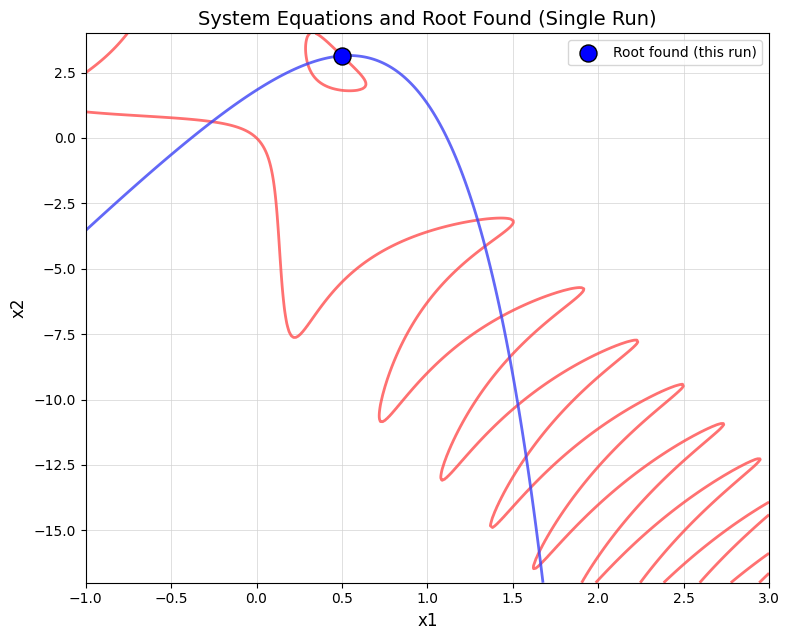

In [ ]:
# Plot the zero-level contour of each equation; intersections = roots
xx, yy = np.meshgrid(np.linspace(-1, 3, 300), np.linspace(-17, 4, 300))

plt.figure(figsize=(8, 6.5))
for eq, color in zip(equations, ['#ff4d4d', '#3b42f5']):
    Z = np.array([[eq(np.array([a, b])) for a, b in zip(rx, ry)]
                  for rx, ry in zip(xx, yy)])
    plt.contour(xx, yy, Z, levels=[0], colors=color, alpha=0.8, linewidths=2)

plt.scatter(root[0], root[1], marker='o', facecolor='blue', edgecolor='black',
            s=150, linewidths=1, label='Root found (this run)', zorder=10)
plt.title('System Equations and Root Found (Single Run)', fontsize=14)
plt.xlabel('x1', fontsize=12); plt.ylabel('x2', fontsize=12)
plt.grid(True, color='lightgray', linestyle='-', linewidth=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Exercise — Try it yourself: Problem 1

Before moving on, try repeating the single-run experiment above on a different system, Problem 1 from Sidarto & Kania (2015):

$$
\begin{cases}
e^{x_1 - x_2} - \sin(x_1 + x_2) = 0 \\
x_1^2 x_2^2 - \cos(x_1 + x_2) = 0
\end{cases}
$$

on the domain $D = [-10, 10] \times [-10, 10]$. This system has 6 distinct roots. Run the cell below a few times with different random seeds. Which root do you land on each time? Does it ever land on the same one twice in a row?

In [ ]:
from pysne.utils import objective_function
from pysne.optimizers.sdoa.engine import spiral_dynamics_optimization

# Define the two equations of Problem 1 (from the system shown above)
equations_p1 = [
     lambda x: np.e**(x[0]-x[1])-np.sin(x[0]+x[1]) ,
     lambda x: (x[0]*x[1])**2-np.cos(x[0]+x[1])
]

# Build the fitness F(x) = 1 / (1 + sum|f_i(x)|) using objective_function
fitness_p1 = lambda x: objective_function(x, equations)

domain_p1 = [(-10, 10), (-10, 10)]

# Choose the SPO parameters (paper uses m=250, r=0.95, theta=pi/4, k_max=270)
params_p1 = {'m': 250, 'r': 0.95, 'theta': np.pi/4, 'k_max': 270}

# The engine's default Sobol init is deterministic, so we feed a fresh RANDOM
# population. Re-run the cell to get a different starting population each time.
lo = np.array([d[0] for d in domain_p1])
hi = np.array([d[1] for d in domain_p1])
init_p1 = np.random.uniform(lo, hi, (params_p1['m'], 2))

root_p1, hist_p1 = spiral_dynamics_optimization(
    fitness_p1, domain_p1, params_p1,
    custom_initial_points=init_p1,        # overrides the deterministic Sobol init
    equations=equations_p1,
    return_history=True,
)

print("Root found :", np.round(root_p1, 6))
print("F(root)    :", hist_p1[-1])
print("Residuals  :", [float(abs(f(root_p1))) for f in equations_p1])

Root found : [0.299449 2.836929]
F(root)    : 0.9999997399289188
Residuals  : [0.07385065338763051, 1.721663352342783]


### 3.1 Why repeated single runs are not enough

A single SPO run converges to just one root, and which root it finds depends entirely on the random initial points: different initializations fall into different convergence regions. A straightforward approach, therefore, is to run SPO many times and simply collect the distinct roots.

Using the SPO parameters ($m = 300$, $r = 0.95$, $\theta = \pi/4$, $k_{\max} = 300$), we repeat the search on the same Problem 2 system 100 times, each with a different random uniform initialization, and count how often each distinct root is found (grouping results closer than 0.05 as the same root):

In [ ]:
import numpy as np
from pysne.utils import objective_function
from pysne.optimizers.sdoa.engine import spiral_dynamics_optimization

# Problem 2 (Sidarto & Kania, 2015)
equations = [
    lambda x: 0.5 * np.sin(x[0] * x[1]) - 0.25 * x[1]/np.pi - 0.5 * x[0],
    lambda x: (1 - 0.25/np.pi) * (np.exp(2*x[0]) - np.e) + np.e * x[1]/np.pi - 2*np.e*x[0]
]

# Fitness: F(x) = 1 / (1 + sum |f_i(x)|), maximized
fitness = lambda x: objective_function(x, equations)

domain_sne = [(-1, 3), (-17, 4)]

# SPO Parameter (Problem 2): m=300, r=0.95, theta=pi/4, k_max=300
params = {'m': 300, 'r': 0.95, 'theta': np.pi / 4, 'k_max': 300}

In [ ]:
from pysne.utils import is_in_domain
import pandas as pd

N_RUNS = 100
lo = np.array([d[0] for d in domain_sne])
hi = np.array([d[1] for d in domain_sne])

found = []
for run in range(N_RUNS):
    rng = np.random.RandomState(run)                      # reproducible per-run seed
    init = rng.uniform(lo, hi, (params['m'], 2))          # RANDOM UNIFORM initialization
    r_found, h = spiral_dynamics_optimization(
        fitness, domain_sne, params,
        custom_initial_points=init,
        equations=equations, epsilon=1e-9,                # early stop when 1 - F <= eps
        return_history=True)
    found.append((r_found, h[-1]))

# Group unique solutions (distance < 0.05) and count frequencies
unique = []                                               # [coords, count, best_F]
for r_found, F in found:
    for u in unique:
        if np.linalg.norm(r_found - u[0]) < 0.05:
            u[1] += 1; u[2] = max(u[2], F); break
    else:
        unique.append([r_found.copy(), 1, F])
unique.sort(key=lambda u: -u[1])

df_runs = pd.DataFrame([{
    'x1': round(c[0], 5), 'x2': round(c[1], 5),
    'frequency': n, 'percentage': f"{n / N_RUNS * 100:.1f}%",
    'best F': f"{F:.8f}", 'in domain': is_in_domain(c, domain_sne),
} for c, n, F in unique])
print(f"{N_RUNS} independent runs -> {len(unique)} distinct solutions obtained:")
df_runs

100 independent runs -> 8 distinct solutions obtained:


,x1,x2,frequency,percentage,best F,in domain
0,0.29945,2.83693,47,47.0%,1.00000000,True
1,0.50000,3.14159,40,40.0%,1.00000000,True
2,-0.26060,0.62253,5,5.0%,0.99999998,True
3,1.29436,-3.13722,4,4.0%,0.99999996,True
4,1.66342,-16.28279,1,1.0%,0.99999996,True
5,1.43395,-6.82077,1,1.0%,0.99999998,True
6,1.48132,-8.38361,1,1.0%,0.99999994,True
7,1.65458,-15.81919,1,1.0%,0.99999991,True


Two problems are now visible from the frequency table. First, the distribution
is heavily biased: 87% of all runs collapse onto just two roots, four other
roots were hit only once each, and the rest fall somewhere in between. Second,
coverage is incomplete — even after 100 independent runs, only 8 of the 12
known roots have been found; a third of the solutions were never discovered at
all. Since each SPO run converges to a single root, and there is no mechanism
steering different runs toward different basins, repeating single runs is an
inefficient and unreliable way to enumerate all solutions. This is where the
clustering technique comes in.

## 4. Clustering — Finding All Roots

The `solve_system` pipeline operates in three phases (Sidarto & Kania, 2015):

1. Clustering phase — scatter `m_cluster` points (Sobol), run a few spiral steps, detect promising regions as *clusters*;
2. Spiral Optimization Phase (SPO per cluster) — run full SPO within each cluster (one root per cluster);
3. Selection & validation — validate candidates against the `epsilon` residual tolerance and filter unique roots using `delta`.

Parameter dictionary:

| Group | Parameter | Meaning |
|---|---|---|
| Clustering | `m_cluster` | number of initial points |
| | `k_cluster` | spiral iterations per clustering cycle |
| | `r_cl`, `theta_cl` | spiral parameters for the clustering phase |
| | `gamma` | fitness threshold for retained points |
| SPO | `spo_m`, `spo_k_max`, `r`, `theta` | SPO parameters per cluster |
| Selection | `epsilon` | residual tolerance for valid roots |
| | `delta` | minimum distance between unique roots |

PySNE provides ready-to-use benchmark problems with pre-calibrated parameters:

In [ ]:
from pysne.problems.benchmarks_sne import get_problem_set
from pysne.solver import solve_system
from pysne.problems.base import SNEProblem

class problem_2(SNEProblem):
    @property
    def name(self):
        return "Problem 2 Benchmark System Non-linear Equation"

    def get_equations(self):
        equations = [
            lambda x: 0.5 * np.sin(x[0] * x[1]) - 0.25 * x[1]/np.pi - 0.5 * x[0],
            lambda x: (1 - 0.25/np.pi) * (np.exp(2*x[0]) - np.e) + np.e * x[1]/np.pi - 2*np.e*x[0]
        ]
        return equations

    def get_info(self):
        domain = [(-1, 3), (-17, 4)]
        params = {
            'm_cluster': 2000,
            'r_cl': 0.95, # r
            'theta_cl': np.pi/4, # theta
            'k_cluster': 10,
            'epsilon': 1e-7,
            'delta': 0.1,
            'sdoa_m': 300,
            'sdoa_k_max': 300,
            'r': 0.95, # sdoa_r
            'theta': np.pi/4, # sdoa_theta
            'gamma': 0.3
        }
        return domain, params

# built-in alternatives
# problems_sne = get_problem_set()
# prob_sne = problems_sne[2]()
prob_sne = problem_2()

domain, params = prob_sne.get_info()
print("Problem :", prob_sne.name)
print("Domain  :", domain)

result = solve_system(prob_sne, params, verbose=True)

Problem : Problem 2 Benchmark System Non-linear Equation
Domain  : [(-1, 3), (-17, 4)]


/usr/local/lib/python3.12/dist-packages/pysne/initialization/sampling.py:36: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  unit_points = sampler.random(n=num_points)


Search completed in 70.000 seconds.
Found 126 clusters and 12 valid roots.


In [ ]:
# Table of roots + individual residuals
all_roots = result['roots']
df = pd.DataFrame(all_roots, columns=['x1', 'x2'])
df['total_residual'] = [
    sum(abs(f(x)) for f in prob_sne.get_equations()) for x in all_roots
]
df.round(8)

,x1,x2,total_residual
0,-0.260599,0.622531,3.000000e-08
1,0.299449,2.836928,4.000000e-08
2,0.500000,3.141593,4.000000e-08
3,1.433949,-6.820765,4.000000e-08
4,1.654583,-15.819188,5.000000e-08
5,1.578225,-12.176690,6.000000e-08
6,1.530505,-10.202248,6.000000e-08
7,1.294360,-3.137220,6.000000e-08
8,1.663422,-16.282791,6.000000e-08
9,1.604571,-13.362902,7.000000e-08


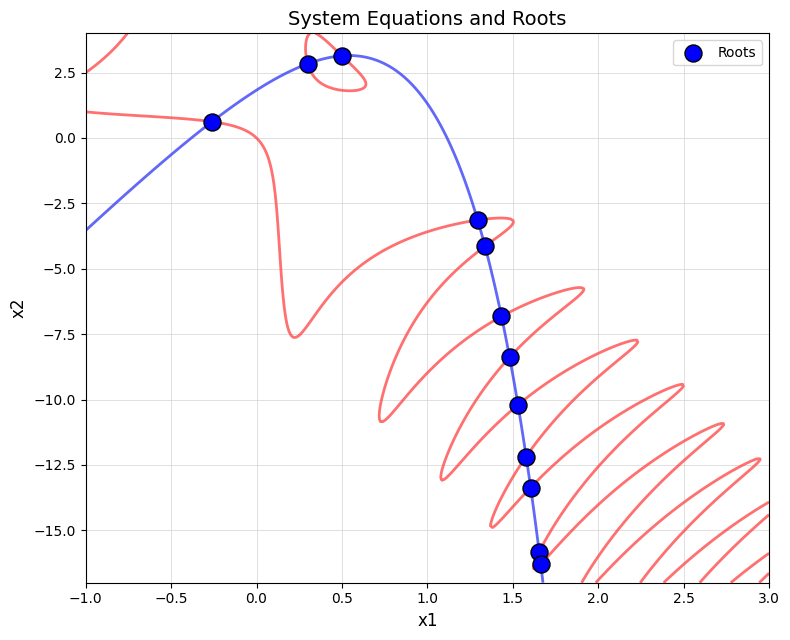

In [ ]:
import matplotlib.pyplot as plt

# Plot all roots found by solve_system on the equation contours
plt.figure(figsize=(8, 6.5))
for eq, color in zip(prob_sne.get_equations(), ['#ff4d4d', '#3b42f5']):
    Z = np.array([[eq(np.array([a, b])) for a, b in zip(rx, ry)]
                  for rx, ry in zip(xx, yy)])
    plt.contour(xx, yy, Z, levels=[0], colors=color, alpha=0.8, linewidths=2)

all_roots = np.array(result['roots'])
plt.scatter(all_roots[:, 0], all_roots[:, 1], marker='o', facecolor='blue',
            edgecolor='black', s=150, linewidths=1, label='Roots', zorder=10)
plt.title('System Equations and Roots', fontsize=14)
plt.xlabel('x1', fontsize=12); plt.ylabel('x2', fontsize=12)
plt.grid(True, color='lightgray', linestyle='-', linewidth=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 4.1 Defining your own SNE problem

Simply subclass `SNEProblem` and implement three things: `name`, `get_equations()`, and `get_info()`:

In [ ]:
from pysne.problems.base import SNEProblem

class MyProblem(SNEProblem):
    @property
    def name(self):
        return "Example: circle & hyperbola"

    def get_equations(self):
        # x^2 + y^2 = 4  and  xy = 1  ->  4 roots
        return [
            lambda x: x[0]**2 + x[1]**2 - 4,
            lambda x: x[0] * x[1] - 1,
        ]

    def get_info(self):
        domain = [(-3, 3), (-3, 3)]
        params = {
            'm_cluster': 512, 'k_cluster': 10,
            'r_cl': 0.95, 'theta_cl': np.pi / 4,
            'gamma': 0.5,                    # recommended for SNE
            'sdoa_m': 128, 'sdoa_k_max': 400,
            'r': 0.95, 'theta': np.pi / 4,
            'epsilon': 1e-7, 'delta': 0.01,
            'expected_roots': 4,
        }
        return domain, params

my_prob = MyProblem()
domain, params = my_prob.get_info()
my_result = solve_system(my_prob, params, verbose=True)
print(np.round(my_result['roots'], 6))

Search completed in 3.175 seconds.
Found 29 clusters and 4 valid roots.
[[-0.517638 -1.931852]
 [ 1.931852  0.517638]
 [-1.931852 -0.517638]
 [ 0.517638  1.931852]]


## 5. Diophantine Equations — Integer Solutions

PySNE can also solve Diophantine equations by combining continuous optimization with integer rounding. Since Spiral Optimization operates in a continuous domain, each integer value is represented by a continuous interval of width 1 (integer bounds ±0.5). During objective evaluation, every candidate solution is rounded to the nearest integer before computing the equation residual.

As a simple example, consider the Diophantine equation

$$
15x + 11y = 12, \qquad x, y \in [-50, 50] \cap \mathbb{Z}.
$$

The search is performed over the corresponding continuous domain, while only rounded integer values are evaluated. Within the bounded search space, this equation has exactly 7 integer solutions, all of which are successfully identified by PySNE in less than one second.

The implementation is very similar to defining an SNE problem. The only difference is that the search domain is specified over integers, while PySNE internally performs optimization over the corresponding continuous intervals.

In [ ]:
from pysne.problems.base import DiophantineProblem

class MyDiophantineProblem(DiophantineProblem):
    @property
    def name(self):
        return "Example: 15x + 11y = 12"

    def get_equations(self):
        return [lambda x: 15*x[0] + 11*x[1] - 12]

    def get_info(self):
        domain = [(-50, 50), (-50, 50)]
        params = {
            'm_cluster': 375, 'k_cluster': 10,
            'r_cl': 0.95, 'theta_cl': np.pi/4,
            'gamma': 0.01,
            'sdoa_m': 30, 'sdoa_k_max': 10,
            'r': 0.95, 'theta': np.pi/4,
            'epsilon': 1e-7, 'delta': 0.1,
            'num_check_points': 3,
            'expected_roots': 7,
        }
        return domain, params

my_prob = MyDiophantineProblem()
domain, params = my_prob.get_info()
result = solve_system(my_prob, params, verbose=True)
print(np.round(result['roots'], 6))

### Try it yourself

Now fill in the template below (next cell) with your own Diophantine equation.

Not sure what to try? Here are a few example problems (already defined further below) —
just instantiate the class and run `solve_system`:
- `DiophantineProblem3a` — a simple cubic equation, 2 variables
- `DiophantineProblem6a` — an exponential mix, 4 variables
- `DiophantineProblem9a` — a Pell equation, 3 variables
- `DiophantineProblem4_4` — a symmetric equation, 4 variables

You have to pick one, edit the name and equations in the template cell,
or directly instantiate one of the example classes below!

In [ ]:
from pysne.problems.base import DiophantineProblem
from pysne.solver import solve_system

class MyDiophantineProblem(DiophantineProblem):
    @property
    def name(self):
        return "TODO: name your problem"

    def get_equations(self):
        # write your Diophantine equation here, e.g.: 7x + 5y - 3
        return [
            lambda x: 7*x[0]-14*x[1],   # 7*x[0] + 5*x[1] - 3
        ]

    def get_info(self):
        domain = [(-20, 20), (-20, 20)]   # set the bounds for x, y (integers)
        params = {        # set the params
            'm_cluster': 375,
            'k_cluster': 10,
            'r_cl': 0.95,
            'theta_cl': np.pi/4,
            'gamma': 0.01,
            'sdoa_m': 30,
            'sdoa_k_max': 10,
            'r': 0.95,
            'theta': np.pi/4,
            'epsilon': 1e-7,
            'delta': 0.1,
        }
        return domain, params

my_prob = MyDiophantineProblem()
domain, params = my_prob.get_info()
result = solve_system(my_prob, params, verbose=True)
print(np.round(result['roots'], 6))

/usr/local/lib/python3.12/dist-packages/pysne/initialization/sampling.py:36: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  unit_points = sampler.random(n=num_points)


Search completed in 0.235 seconds.
Found 22 clusters and 18 valid roots.
[[  0.   0.]
 [ 18.   9.]
 [ 14.   7.]
 [  6.   3.]
 [ -6.  -3.]
 [-16.  -8.]
 [ 12.   6.]
 [ 16.   8.]
 [  4.   2.]
 [  8.   4.]
 [  2.   1.]
 [ -8.  -4.]
 [-14.  -7.]
 [ -4.  -2.]
 [-12.  -6.]
 [ 10.   5.]
 [-10.  -5.]
 [ -2.  -1.]]


In [ ]:
# Diophantine Equations

class DiophantineProblem3a(DiophantineProblem):
    @property
    def name(self):
        return "Cubic: x1^3 + x2^3 = 1008"

    def get_equations(self):
        return [lambda var: var[0]**3 + var[1]**3 - 1008]

    def get_info(self):
        domain = [(1, 10), (1, 10)]
        params = {}
        return domain, params


class DiophantineProblem6a(DiophantineProblem):
    @property
    def name(self):
        return "Exponential Mix: x^2 + 2^a * 11^b = y^3"

    def get_equations(self):
        return [lambda var: var[0]**2 + (2**var[2]) * (11**var[3]) - var[1]**3]

    def get_info(self):
        domain = [(0, 20)] * 4
        params = {}
        return domain, params


class DiophantineProblem9a(DiophantineProblem):
    @property
    def name(self):
        return "Pell Equation (p=2)"

    def get_equations(self):
        return [
            lambda v: v[0]**2 - 24*(v[1]**2) - 1,
            lambda v: v[1]**2 - 2*(v[2]**2) - 1
        ]

    def get_info(self):
        domain = [(400, 500), (1, 100), (1, 100)]
        params = {}
        return domain, params


class DiophantineProblem4_4(DiophantineProblem):
    @property
    def name(self):
        return "Symmetric: x1^2+x2^2+x3^2+x4^2 = 4*x1*x2*x3*x4"

    def get_equations(self):
        return [lambda var: var[0]**2 + var[1]**2 + var[2]**2 + var[3]**2
                - 4 * var[0] * var[1] * var[2] * var[3]]

    def get_info(self):
        domain = [(1, 200), (1, 20), (1, 5), (1, 5)]
        params = {}
        return domain, params

##6. Speed Reducer Design Optimization (Mixed-Integer)

This example applies the Spiral Optimization Algorithm (SPO) from
PySNE to a classic constrained engineering benchmark: the speed
reducer design problem.

#### Modification for (Mixed) Integer Programming

Suppose among the variables $x_1, x_2, \dots, x_n$, a subset
$x_1, \dots, x_i$ must be integer-valued. The modification is simple:
before evaluating $F(\mathbf{x})$, these variables are converted to integer
type (rounded). The spiral search itself remains in continuous space.

Here, only $x_3$ is an integer variable.

#### Problem Formulation

Minimize the total weight:

$$
\begin{aligned}
f(\mathbf{x}) ={}& 0.7854\,x_1 x_2^2\left(3.3333\,x_3^2 + 14.9334\,x_3 - 43.0934\right) \\
&- 1.508\,x_1\left(x_6^2 + x_7^2\right) + 7.4777\left(x_6^3 + x_7^3\right)
+ 0.7854\left(x_4 x_6^2 + x_5 x_7^2\right)
\end{aligned}
$$

subject to 11 inequality constraints $g_i(\mathbf{x}) \le 0$ and bounds:
$x_1 \in [2.6, 3.6]$, $x_2 \in [0.7, 0.8]$, $x_3 \in [17, 28]$ (integer),
$x_4 \in [7.3, 8.3]$, $x_5 \in [7.8, 8.3]$, $x_6 \in [2.9, 3.9]$, $x_7 \in [5.0, 5.5]$.

In [ ]:
import time
import numpy as np
from pysne.problems.base import MultimodalProblem, MinimizedProblem
from pysne.utils import is_in_domain, filter_unique_roots, create_continuous_bounds
from pysne.solver import solve

LOW  = np.array([2.6, 0.7, 17.0, 7.3, 7.8, 2.9, 5.0])
HIGH = np.array([3.6, 0.8, 28.0, 8.3, 8.3, 3.9, 5.5])
INTEGER_IDX = [2]            # only x3 (number of teeth) is integer
M_PENALTY = 1e15

def f_vec(X):
    """Objective: total weight."""
    x1, x2, x3, x4, x5, x6, x7 = X.T
    return (0.7854 * x1 * x2**2 * (3.3333 * x3**2 + 14.9334 * x3 - 43.0934)
           - 1.508 * x1 * (x6**2 + x7**2)
           + 7.4777 * (x6**3 + x7**3)
           + 0.7854 * (x4 * x6**2 + x5 * x7**2))

def constraints_vec(X):
    """The 11 constraints g_i(x) <= 0."""
    x1, x2, x3, x4, x5, x6, x7 = X.T
    g = np.empty((X.shape[0], 11))
    g[:, 0]  = 27 / (x1 * x2**2 * x3) - 1
    g[:, 1]  = 397.5 / (x1 * x2**2 * x3**2) - 1
    g[:, 2]  = (1.93 * x4**3) / (x2 * x3 * x6**4) - 1
    g[:, 3]  = (1.93 * x5**3) / (x2 * x3 * x7**4) - 1
    g[:, 4]  = (1.0 / (110 * x6**3)) * np.sqrt((745.0 * x4 / (x2 * x3))**2 + 16.9e6) - 1
    g[:, 5]  = (1.0 / (85 * x7**3)) * np.sqrt((745.0 * x5 / (x2 * x3))**2 + 157.5e6) - 1
    g[:, 6]  = (x2 * x3) / 40 - 1
    g[:, 7]  = (5 * x2) / x1 - 1
    g[:, 8]  = x1 / (12 * x2) - 1
    g[:, 9]  = (1.5 * x6 + 1.9) / x4 - 1
    g[:, 10] = (1.1 * x7 + 1.9) / x5 - 1
    return g


class SpeedReducerProblem(MultimodalProblem):
    @property
    def name(self):
        return "Speed Reducer Design (Mixed-Integer, Clustering)"

    def g_func(self, x):
        X = np.atleast_2d(np.asarray(x, dtype=float))
        Q = X.copy()
        for idx in INTEGER_IDX:
            Q[:, idx] = np.round(Q[:, idx])
        inside = np.all((Q >= LOW) & (Q <= HIGH), axis=1)
        out = np.full(Q.shape[0], M_PENALTY)
        if inside.any():
            Xin = Q[inside]
            g = constraints_vec(Xin)
            viol = np.sum(np.maximum(0.0, g), axis=1)
            out[inside] = f_vec(Xin) + M_PENALTY * viol
        return out[0] if np.asarray(x).ndim == 1 else out

    def select_final_optimal(self, candidates):
        domain, params = self.get_info()
        delta = params.get('delta', 0.5)
        scored = [(c, self.evaluate_fitness(c)) for c in candidates if is_in_domain(c, domain)]
        return filter_unique_roots(scored, delta)

    def get_info(self):
        margin = np.where(np.isin(np.arange(7), INTEGER_IDX), 0.5, 0.0)
        domain = list(zip(LOW - margin, HIGH + margin))
        params = {
            'm_cluster': 125, 'k_cluster': 50,
            'r_cl': 0.95, 'theta_cl': np.pi/4,
            'gamma': 0.1,
            'sdoa_m': 30000, 'sdoa_k_max': 750,
            'r': 0.99, 'theta': np.pi/4,
            'epsilon': 1e-7, 'delta': 0.01,
        }
        return domain, params


# ------------------ RUN ------------------

prob = MinimizedProblem(SpeedReducerProblem())
domain, params = prob.get_info()

print("Running Speed Reducer (Mixed-Integer) optimization with Clustering + SPO...")
print(f"Cluster pop: {params['m_cluster']}, Cluster iters: {params['k_cluster']}, "
      f"SDOA pop: {params['sdoa_m']}, SDOA max iters: {params['sdoa_k_max']}, "
      f"r={params['r']}, theta=pi/{int(round(np.pi / params['theta']))}")

t0 = time.perf_counter()
result = solve(prob, params, verbose=True)
elapsed = time.perf_counter() - t0

# ------------------ COLLECT CANDIDATES ------------------

rows = []
for o in result['optimals']:
    Q = o.copy()
    Q[2] = round(Q[2])
    w = f_vec(Q[None])[0]
    g = constraints_vec(Q[None])[0]
    rows.append((w, np.all(g <= 1e-6), Q, g))
rows.sort(key=lambda r: r[0])

# ------------------ DISPLAY RESULTS ------------------

feasible_rows = [r for r in rows if r[1]]
best_w, best_feasible, best_x, best_g = (feasible_rows[0] if feasible_rows else rows[0])

final_x = best_x
final_f_x = best_w
g_final = best_g
violation_sum_final = np.sum(np.maximum(0, g_final))
final_penalty = final_f_x + M_PENALTY * violation_sum_final if not best_feasible else final_f_x

print("\n" + "=" * 60)
print("SPEED REDUCER OPTIMIZATION RESULTS")
print("=" * 60)
for i in range(7):
    val = f"{int(final_x[i])}" if i == 2 else f"{final_x[i]:.6f}"
    print(f"x{i+1}  = {val}")
print("-" * 60)
print(f"Actual objective f(x)  = {final_f_x:.8f}")
print(f"Penalized value F(x)   = {final_penalty:.8f} (= f(x) if feasible)")

violations = g_final[g_final > 0]
if len(violations) == 0:
    print("\nSTATUS: FEASIBLE (all g_i <= 0)")
else:
    print(f"\nSTATUS: INFEASIBLE ({len(violations)} constraint(s) still violated)")
    print(f"Violating g_i values: {violations}")

print("\nAll g_i values:")
for i, gi in enumerate(g_final, 1):
    print(f"  g{i:2d} = {gi:.6e}")

print(f"\nExecution time: {elapsed:.2f} s")

Running Speed Reducer (Mixed-Integer) optimization with Clustering + SPO...
Cluster pop: 125, Cluster iters: 50, SDOA pop: 30000, SDOA max iters: 750, r=0.99, theta=pi/4
Search completed in 12.652 seconds.
Found 1 clusters and 1 valid optimal solutions.

SPEED REDUCER OPTIMIZATION RESULTS
x1  = 3.500002
x2  = 0.700000
x3  = 17
x4  = 7.812675
x5  = 7.801015
x6  = 3.351212
x7  = 5.286684
------------------------------------------------------------
Actual objective f(x)  = 3001.14825289
Penalized value F(x)   = 3001.14825289 (= f(x) if feasible)

STATUS: FEASIBLE (all g_i <= 0)

All g_i values:
  g 1 = -7.391606e-02
  g 2 = -1.979992e-01
  g 3 = -3.868003e-01
  g 4 = -9.014333e-01
  g 5 = -6.378758e-06
  g 6 = -4.227906e-08
  g 7 = -7.025000e-01
  g 8 = -4.886077e-07
  g 9 = -5.833331e-01
  g10 = -1.133871e-01
  g11 = -1.098106e-02

Execution time: 12.65 s


## 7. Multimodal Optimization — All Optima

For multimodal functions, the goal is to find *all* optima of the function (not just the single global optimum).

The clustering framework from Sections 3–4 carries over almost unchanged, but a few mechanisms are adapted for the multimodal case. The table below summarizes how each stage differs between root-finding (SNE) and multimodal optimization:

| Stage | SNE | Multimodal |
|---|---|---|
| Objective function | Transform $f(\mathbf{x})=0$ into $F(\mathbf{x})$ | No transformation; $F(\mathbf{x})$ evaluated directly |
| Optimum target | Static & absolute: $F(\mathbf{x}^*)=1$ | Dynamic & relative: $f_{\max}/f_{\min}$ depends on the function landscape |
| Cutoff $\gamma$ | $F(\mathbf{x}_i) > \gamma$ | Relative: $F(\mathbf{x}_i) > \gamma\,F(\mathbf{x}_{\text{best}})$ |
| Local intensification | SPO converges points toward the value 1 | SPO converges points toward each optimum (peak / valley) |
| Final convergence | $1 - F(\mathbf{x}) < \varepsilon$ (absolute target value) | $F(\mathbf{x}) > F(\mathbf{x} + \varepsilon)$ & $F(\mathbf{x}) > F(\mathbf{x} - \varepsilon)$ |
| Output | Set of roots ($f(\mathbf{x}) \approx 0$) | Set of optimal points (max & min) |

The overall algorithmic framework is preserved; only the clustering, convergence, and solution-selection mechanisms are modified so that it can locate many optimal of a multimodal function.

As a first example, we use the Six-Hump Camel Back function.

In [ ]:
import numpy as np
from pysne.solver import solve
from pysne.problems.base import MultimodalProblem, MinimizedProblem
# from pysne.problems.benchmarks_multimodal import get_multimodal_problems

# 1. Define the problem (example: Six-Hump Camel Back)
# Built-in alternative:
# problems = get_multimodal_problems()
# prob = problems[2]()

class Problem2(MultimodalProblem):
    @property
    def name(self):
        return "Problem 2: Six Hump Camel Back Function"

    def g_func(self, x):
        x = np.asarray(x)
        x1 = x[0] if x.ndim == 1 else x[:, 0]
        x2 = x[1] if x.ndim == 1 else x[:, 1]
        term1 = (4 - 2.1 * x1**2 + (x1**4) / 3) * x1**2
        term2 = x1 * x2
        term3 = (-4 + 4 * x2**2) * x2**2
        return (term1 + term2 + term3)

    def get_info(self):
        domain = [(-1.9, 1.9), (-1.1, 1.1)]
        params = {
            'm_cluster': 300,
            'r_cl': 0.95,
            'theta_cl': np.pi/4,
            'k_cluster': 5,
            'epsilon': 1e-5,
            'delta': 0.1,
            'sdoa_m': 50,
            'sdoa_k_max': 250,
            'r': 0.95,
            'theta': np.pi/4,
            'gamma': -float('inf'),
            'num_check_points': 2
        }
        return domain, params

prob_mm = Problem2()

# 2. Get the pre-calibrated domain and default parameters
domain, params = prob_mm.get_info()

# 3. Run the solver -> searches for MAXIMUM points
result_max = solve(prob_mm, params, verbose=True)

print(result_max['optimals'])        # array of solution coordinates
print(result_max['time_elapsed'])    # execution time (seconds)
print(f"Maximum found: {len(result_max['optimals'])} points")

Search completed in 0.990 seconds.
Found 93 clusters and 2 valid optimal solutions.
[[ 1.23022988  0.16233459]
 [-1.23022988 -0.16233459]]
0.9895031452178955
Maximum found: 2 points


By default the solver searches for maximum; to find minimum, wrap the problem with `MinimizedProblem`:

In [ ]:
from pysne.problems.base import MinimizedProblem
from pysne.solver import solve

# Wrap the same problem to search for MINIMUM points instead
prob_mm_min = MinimizedProblem(prob_mm)

result_min = solve(prob_mm_min, params, verbose=True)

print(result_min['optimals'])        # array of solution coordinates
print(result_min['time_elapsed'])    # execution time (seconds)
print(f"Minimum found: {len(result_min['optimals'])} points")

Search completed in 1.351 seconds.
Found 109 clusters and 6 valid optimal solutions.
[[-0.08984201  0.7126564 ]
 [ 0.08984202 -0.7126564 ]
 [ 1.70360671 -0.79608357]
 [-1.70360672  0.79608356]
 [ 1.60710476  0.56865146]
 [-1.60710474 -0.56865145]]
1.3514461517333984
Minimum found: 6 points


Six Hump Camel Back Function Visualization

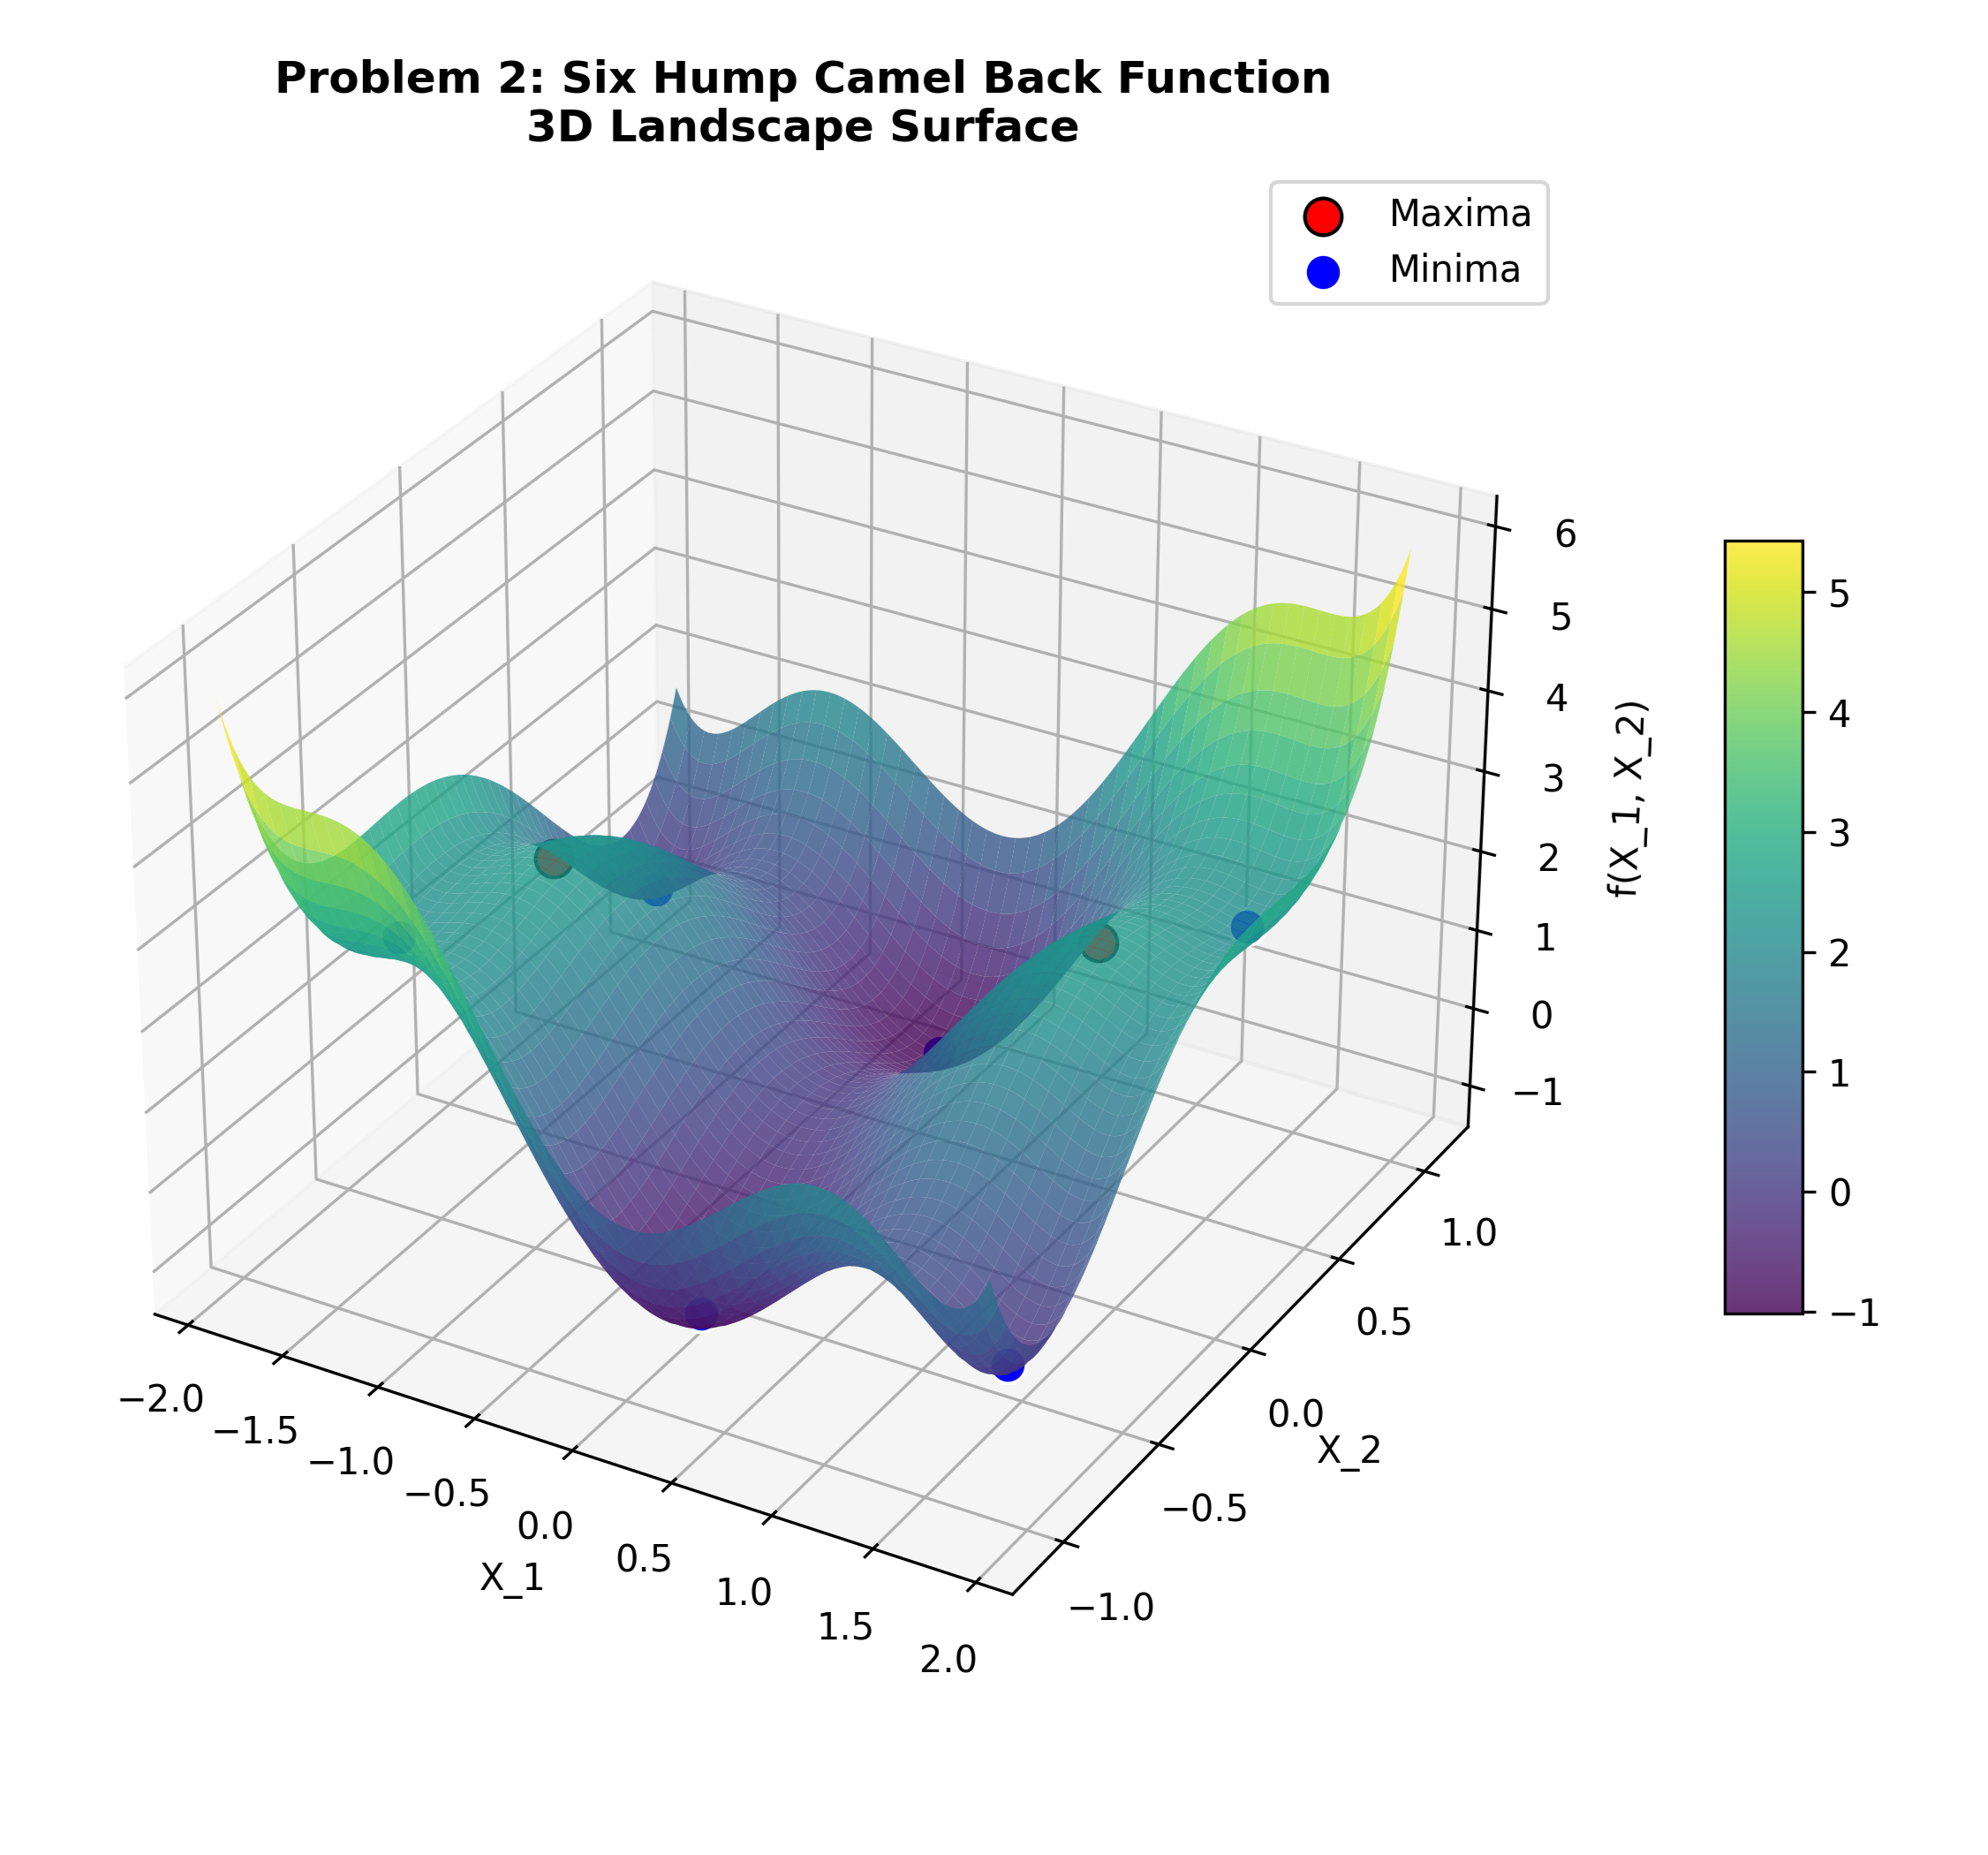

### 7.1 Defining your own multimodal problem

For multimodal optimization, subclass `MultimodalProblem` and implement three
things: `name`, `g_func()` (the objective function, supporting both a single
point of shape `(n,)` and a batch of shape `(k, n)`), and `get_info()`. By
default the solver searches for all maximum of `g_func`; to find all
minimum instead, wrap the problem in `MinimizedProblem` — no changes to the
objective needed.

The example below uses Himmelblau's function, which has four global minima
and one local maximum inside the domain:

In [ ]:
import numpy as np
from pysne.problems.base import MultimodalProblem, MinimizedProblem
from pysne.solver import solve

class MyProblem(MultimodalProblem):
    @property
    def name(self):
        return "MyProblem: Himmelblau's Function"

    def g_func(self, x):
        x = np.asarray(x)
        x1 = x[0] if x.ndim == 1 else x[:, 0]   # batch-safe: (n,) or (k, n)
        x2 = x[1] if x.ndim == 1 else x[:, 1]
        return (x1**2 + x2 - 11)**2 + (x1 + x2**2 - 7)**2

    def get_info(self):
        domain = [(-5, 5), (-5, 5)]
        params = {
            'm_cluster': 512, 'k_cluster': 10, 'gamma': -float('inf'),
            'sdoa_m': 128, 'sdoa_k_max': 400,
            'r': 0.95, 'theta': np.pi / 4,
            'epsilon': 1e-7, 'delta': 0.01,
            'num_check_points': 1
        }
        return domain, params

prob = MyProblem()
domain, params = prob.get_info()

# Search for all maximum of g_func
result_max = solve(prob, params, verbose=True)
print("Maximum found:\n", result_max['optimals'])

# Wrap the same problem to search for all minimum instead
prob_min = MinimizedProblem(prob)
result_min = solve(prob_min, params, verbose=True)
print("Minimum found:\n", result_min['optimals'])

Search completed in 0.995 seconds.
Found 49 clusters and 1 valid optimal solutions.
Maximum found:
 [[-0.27084461 -0.92303852]]
Search completed in 0.734 seconds.
Found 28 clusters and 4 valid optimal solutions.
Minimum found:
 [[ 3.58442834 -1.84812653]
 [ 3.          2.        ]
 [-3.77931025 -3.28318599]
 [-2.80511809  3.13131252]]


### Exercise — Try it yourself: define a multimodal problem

Your turn to build a full multimodal problem from scratch. Implement the 2D Second Minima function:

$$g(x_1, x_2) = \tfrac{1}{2}\sum_{i=1}^{2}\left(x_i^4 - 16\,x_i^2 + 5\,x_i\right)$$

It has **four** minima on $x_1, x_2 \in [-4, 4]$: one global near $(-2.90, -2.90)$ and three secondary ones at the other combinations of $-2.90$ and $2.75$.

In the chunk below, fill in three things yourself — the `g_func` body (the equation), the search `domain`, and the `params`. Because the optima are *minima*, the problem is wrapped in `MinimizedProblem`. Run it: do you recover all four?

In [ ]:
import numpy as np
from pysne.solver import solve
from pysne.problems.base import MultimodalProblem, MinimizedProblem

class SecondMinima(MultimodalProblem):
    @property
    def name(self):
        return "Exercise: 2D Second Minima function"

    def g_func(self, x):
        x = np.asarray(x)
        x1 = x[0] if x.ndim == 1 else x[:, 0]   # batch-safe: (n,) or (k, n)
        x2 = x[1] if x.ndim == 1 else x[:, 1]
        # TODO - implement g(x1, x2) = 0.5 * sum_i (xi**4 - 16*xi**2 + 5*xi)
        return ...

    def get_info(self):
        # TODO - set the search domain for both variables
        domain = [(..., ...), (..., ...)]
        # TODO - fill in the parameters. Reasonable starting point:
        #   m_cluster=300, k_cluster=10, sdoa_m=200, sdoa_k_max=230,
        #   r=r_cl=0.95, theta=theta_cl=pi/4, gamma=-inf, epsilon=1e-7, delta=0.1
        params = {
            'm_cluster': ..., 'k_cluster': ...,
            'r_cl': ..., 'theta_cl': ...,
            'sdoa_m': ..., 'sdoa_k_max': ...,
            'r': ..., 'theta': ...,
            'gamma': ..., 'epsilon': ..., 'delta': ...,
        }
        return domain, params

prob = SecondMinima()
_, params = prob.get_info()

# These optima are MINIMA -> wrap in MinimizedProblem
result = solve(MinimizedProblem(prob), params, verbose=True)
print("Minima found:\n", np.round(result['optimals'], 5))
print(f"{len(result['optimals'])} minima found (expected: 4)")

TypeError: 'ellipsis' object cannot be interpreted as an integer

## 8. Conclusion

Summary of what we covered:

| Section | Capability | Key function |
|---|---|---|
| 2 | Single-objective optimization | `spiral_dynamics_optimization(...)` |
| 3 | Single root via $F(\mathbf{x})$ transformation | `objective_function` + engine |
| 4 | All SNE roots | `solve_system(SNEProblem, params)` |
| 5 | Integer solutions (Diophantine) | `solve_system(DiophantineProblem, params)` |
| 6 | All multimodal optimal | `solve(MultimodalProblem, params)` + `MinimizedProblem` |

Once PySNE is officially released on PyPI, installation will simply be `pip install pysne` and this tutorial will be updated with a pinned stable release tag.

Repository: https://github.com/p2ms-optimization/pysne